# TP 05 : prédire la durée d'un trajet Yellow Taxi

## Imports

In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

## Localiser et lire les données

In [2]:
data_path = Path("data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {data_path}")

data_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

In [3]:
df = pd.read_parquet(data_path)
df.shape

(4090836, 20)

In [4]:
columns = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance"]
df[columns].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance
0,2026-05-01 00:04:59,2026-05-01 00:32:48,138,37,7.51
1,2026-05-01 00:37:05,2026-05-01 00:59:47,138,237,6.14
2,2026-05-01 00:34:05,2026-05-01 00:54:02,249,232,2.40
3,2026-05-01 00:55:07,2026-05-01 01:02:43,232,114,1.20
4,2026-05-01 00:44:13,2026-05-01 00:44:13,140,237,0.86


## Cible : durée en minutes (arrivée moins départ)

In [5]:
df["duration"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

## Filtrer (1 à 60 min), créer PU_DO, échantillonner et trier par date

In [6]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]
df.shape

(3883752, 22)

In [7]:
sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

## Séparation chronologique : 80 % entraînement, 20 % validation (les plus récents)

In [8]:
split_index = int(len(df) * 0.8)
df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()
len(df_train), len(df_val)

(160000, 40000)

## Transformer : fit_transform apprend les colonnes sur le train, transform les réutilise

In [9]:
features = ["PU_DO", "trip_distance"]
train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Correctif : Lasso n'accepte que des index 32 bits dans la matrice creuse
for X in (X_train, X_val):
    X.indices = X.indices.astype("int32")
    X.indptr = X.indptr.astype("int32")

y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()
X_train.shape, X_val.shape

((160000, 12641), (40000, 12641))

## Régression linéaire (modèle de référence). RMSE en minutes : plus bas = mieux

In [10]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_val)
linear_rmse = root_mean_squared_error(y_val, linear_predictions)
linear_rmse

6.652815344851184

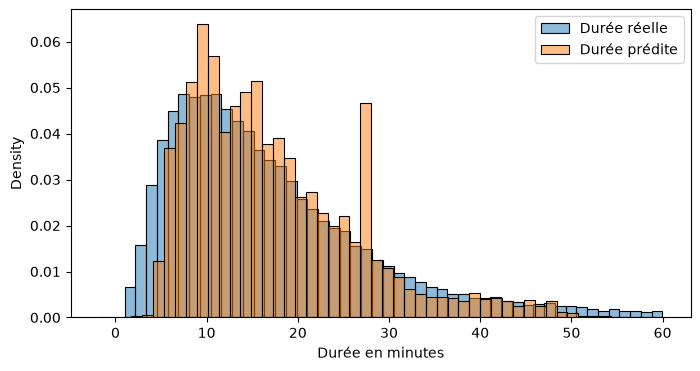

In [11]:
plt.figure(figsize=(8, 4))
sns.histplot(y_val, label="Durée réelle", stat="density", bins=50, alpha=0.5)
sns.histplot(linear_predictions, label="Durée prédite", stat="density", bins=50, alpha=0.5)
plt.xlabel("Durée en minutes")
plt.legend()
plt.show()

## Lasso : régression régularisée (alpha pénalise les coefficients)

In [12]:
lasso_model = Lasso(alpha=0.01, max_iter=10_000)
lasso_model.fit(X_train, y_train)
lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)
lasso_rmse

10.517043400486218

## XGBoost : arbres successifs qui corrigent les erreurs précédentes

In [13]:
xgb_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1,
                         objective="reg:squarederror", random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)
xgb_rmse

6.471618951707119

In [14]:
results = pd.DataFrame({"model": ["LinearRegression", "Lasso", "XGBoost"],
                        "rmse": [linear_rmse, lasso_rmse, xgb_rmse]}).sort_values("rmse")
results

,model,rmse
2,XGBoost,6.471619
0,LinearRegression,6.652815
1,Lasso,10.517043


## Sauvegarder ensemble le DictVectorizer et le meilleur modèle

In [15]:
models = {"LinearRegression": (linear_model, linear_rmse), "Lasso": (lasso_model, lasso_rmse),
          "XGBoost": (xgb_model, xgb_rmse)}
selected_name = min(models, key=lambda name: models[name][1])
selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "duration_model.bin"
with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)
selected_name, selected_rmse, model_path

('XGBoost', 6.471618951707119, PosixPath('models/duration_model.bin'))

## Vérifier le fichier sauvegardé

In [16]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)
example = [{"PU_DO": "161_236", "trip_distance": 3.2}]
prediction = loaded_model.predict(loaded_dv.transform(example))[0]
prediction

np.float32(21.65231)

## Travail à réaliser : deux autres alpha et un paramètre XGBoost modifié (max_depth)

In [17]:
trials = [("Lasso", "alpha=0.01", lasso_rmse), ("XGBoost", "max_depth=6", xgb_rmse),
          ("LinearRegression", "defaut", linear_rmse)]
for alpha in [0.001, 0.1]:
    model = Lasso(alpha=alpha, max_iter=10_000).fit(X_train, y_train)
    trials.append(("Lasso", f"alpha={alpha}", root_mean_squared_error(y_val, model.predict(X_val))))

xgb_deep = XGBRegressor(n_estimators=100, max_depth=10, learning_rate=0.1,
                        objective="reg:squarederror", random_state=42, n_jobs=-1).fit(X_train, y_train)
trials.append(("XGBoost", "max_depth=10", root_mean_squared_error(y_val, xgb_deep.predict(X_val))))

trials_df = pd.DataFrame(trials, columns=["model", "parametre", "rmse"]).sort_values("rmse")
trials_df

,model,parametre,rmse
5,XGBoost,max_depth=10,6.414077
1,XGBoost,max_depth=6,6.471619
2,LinearRegression,defaut,6.652815
3,Lasso,alpha=0.001,7.877294
0,Lasso,alpha=0.01,10.517043
4,Lasso,alpha=0.1,10.977719


In [18]:
# Sauvegarde du modele retenu apres les essais
import sys, sklearn, xgboost
with model_path.open("wb") as output_file:
    pickle.dump((dv, xgb_deep), output_file)
print("XGBoost max_depth=10", root_mean_squared_error(y_val, xgb_deep.predict(X_val)))
print(sys.version.split()[0], pd.__version__, sklearn.__version__, xgboost.__version__)

XGBoost max_depth=10 6.4140769269615205
3.12.16 3.1.0 1.9.1 3.4.2


## Conclusion

**Modèle retenu : XGBoost avec max_depth=10**, car il a la RMSE de validation la plus faible (environ 6,41 min), contre 6,47 pour max_depth=6 et 6,65 pour la régression linéaire. Le gain par rapport à max_depth=6 reste faible. Les trois essais Lasso sont moins bons, et l'erreur augmente avec alpha (la régularisation est trop forte).

**Informations à conserver pour reproduire chaque essai :**
- le fichier de données (yellow_tripdata_2026-05.parquet) ;
- le filtre (durée entre 1 et 60 min), l'échantillon (200 000 lignes au maximum, random_state=42) ;
- la séparation chronologique 80 % / 20 % ;
- les variables (PU_DO, trip_distance) et le DictVectorizer ;
- le type de modèle et tous ses paramètres ;
- la RMSE de validation ;
- les versions de Python et des bibliothèques ;
- le commit Git du code.